# Optimize ViT — Meme MRI, standart 5-fold protokolü

**Modeller:** ViT-B/16, ViT-B/32, ViT-L/16, ViT-L/32, Swin-T
**Bu grubun reçetesi:** Son 4 encoder bloğu (Swin-T: son stage), son norm ve head eğitilir. Reçete Optimize CNN ile birebir aynı: AdamW, lr 1e-4, cosine, augmentation, label smoothing 0,1, dropout 0,3, gradient clipping.

Bu notebook, dört grup notebook'undan biridir (`1_baseline_cnn`, `2_baseline_vit`, `3_optimized_cnn`, `4_optimized_vit`). Dördünün kodu birebir aynıdır; tek fark ilk hücredeki `GROUP` satırıdır. Bu sayede şunlar bütün gruplarda aynı kalır:
- **Veri bölünmesi:** Her fold'da 16.826 train / 3.594 validation / 3.604 test (`holdout5` modu). Fold ataması `folds_holdout5.csv` dosyasına bir kez yazılır ve bütün notebook'lar aynı dosyayı kullanır.
- **Eğitim koşulları:** 10 epoch, etkin batch 32, 224×224 giriş, en iyi epoch en düşük validation loss'a göre seçilir, seed 42.
- **Çıktılar:** Her model ve her fold için train/validation/test confusion matrix'i, ROC eğrisi ve metrik grafiği, accuracy ve loss eğrileri, metrik tablosu.

**Nasıl çalıştırılır:** Colab'da GPU seçip bütün hücreleri sırayla çalıştır. Oturum kesilirse yeniden çalıştırman yeterli; biten fold'lar atlanır. Süre yetmezse ilk hücrede `MODELS = ["ViT-L-16"]` gibi tek bir model verebilirsin.
Dört notebook bittikten sonra `5_tum_sonuclar.ipynb` ile bütün sonuçları tek bir Excel dosyasında birleştir.


In [1]:
# ======================= 1. AYARLAR =======================
from pathlib import Path

# Bu notebook'un deney grubu. DEĞİŞTİRME: her grubun kendi notebook'u var.
GROUP = "optimized_vit"

# None = grubun tüm modelleri. Colab süresi yetmezse tek tek ver: ["ViT-L-16"]
MODELS = None

# RERUN = False        → biten fold'lar atlanır, kaldığı yerden devam eder.
# RERUN = "bir-etiket" → bu gruptaki eski sonuçlar BİR KEZ silinir ve yeniden eğitilir
#   (MODELS = None ise tüm modeller, MODELS = ["InceptionV3"] gibi verilirse sadece onlar).
#   Silme yapıldıktan sonra Drive'a rerun_<etiket>.done dosyası yazılır. Colab kesilip notebook aynen
#   yeniden çalıştırılırsa aynı etiketle bir daha silme YAPILMAZ, kaldığı fold'dan devam eder.
#   Yeni bir temiz çalıştırma için yeni bir etiket ver (ör. tarih).
RERUN = False

# Swin-T eğitilir ve kaydedilir; makaleye girip girmeyeceği ayrı karar
INCLUDE_SWIN = True

# ---------------- 5 katlı çapraz doğrulama (TÜM gruplarda aynı fold'lar) ----------------
# Kaggle train (16.826) + validation (3.594) = 20.420 görüntü havuzu oluşturulur, test (3.604) hiç karışmaz.
#   "kfold"    : Stratified 5-fold. Her fold: ~16.336 train / ~4.084 validation. Her görüntü tam 1 kez validation olur.
#   "holdout5" : 5 tekrarlı stratified hold-out. Her fold: TAM 16.826 train / 3.594 validation (Kaggle sayılarıyla birebir),
#                ama validation kümeleri fold'lar arasında örtüşebilir (klasik k-fold değildir; makalede böyle yazılmalı).
CV_MODE = "holdout5"   # hocanın istediği: her fold Kaggle sayılarıyla birebir aynı
N_FOLDS = 5
FOLD_SEED = 42        # fold ataması bir kez üretilir, folds.csv'ye yazılır; tüm gruplar ve modeller aynı dosyayı kullanır
TRAIN_SEED = 42       # her fold'da model eğitimi için aynı seed

# Veri kaynağı: "kaggle" (önerilen; train/validation/test klasörleriyle iner) veya "rar"
DATA_SOURCE = "kaggle"
KAGGLE_ID = "abenjelloun/breast-mri-tumor-classification-dataset"
RAR_SOURCE = "/content/drive/MyDrive/data_set_zip/breast_mri_dataset.rar"   # rar'da validation klasörü de olmalı

EXPECTED_COUNTS = {"train": 16826, "val": 3594, "test": 3604}
STRICT_COUNTS = True                  # sayılar tutmazsa dur

# Sonuçlar Drive'a yazılır (Colab kapanınca kaybolmasın, kaldığı yerden devam edebilsin)
OUTPUT_ROOT = Path("/content/drive/MyDrive/breast_mri_standard_results")

SHOW_PLOTS = True                     # grafikleri hücre altında da göster

# ---------------- Tüm gruplarda ORTAK protokol ----------------
COMMON = dict(
    img_size=224,
    epochs=10,                 # her run sabit 10 epoch, early stopping yok
    batch_size=32,             # fiziksel batch
    accum_steps=1,             # bellek yetmezse batch_size=16, accum_steps=2 (etkin batch yine 32)
    num_workers=2,
    amp=True,                  # mixed precision (hız için, tüm gruplarda açık)
    select_by="val_loss",      # en iyi epoch: en düşük validation loss (tüm gruplarda aynı)
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225],
)

# ---------------- Grup reçeteleri ----------------
# Baseline: yalnızca sınıflandırma başı eğitilir, augmentation/regularization yok.
# Optimize: CNN ve ViT için AYNI reçete; tek fark hangi katmanların açıldığı (FT_SCOPE).
RECIPES = {
    "baseline": dict(optimizer="adam", lr=1e-3, weight_decay=0.0, scheduler=None,
                     augment=False, label_smoothing=0.0, head_dropout=0.0, grad_clip=None),
    "optimized": dict(optimizer="adamw", lr=1e-4, weight_decay=1e-4, scheduler="cosine", eta_min=1e-6,
                      augment=True, label_smoothing=0.1, head_dropout=0.3, grad_clip=1.0),
}
FT_SCOPE = {
    ("baseline", "cnn"): "head",
    ("baseline", "vit"): "head",
    ("optimized", "cnn"): "full",      # tüm katmanlar
    ("optimized", "vit"): "partial",   # ViT: son 4 encoder bloğu + son LayerNorm + head; Swin-T: son stage + norm + head
}
VIT_LAST_BLOCKS = 4

AUGMENT = dict(rotation=15, hflip_p=0.5, vflip_p=0.5, translate=0.05, scale=(0.95, 1.05),
               brightness=0.15, contrast=0.15, erasing_p=0.15)

CNN_MODELS = ["ResNet34", "DenseNet121", "EfficientNet-B0", "MobileNetV2", "InceptionV3"]
VIT_MODELS = ["ViT-B-16", "ViT-B-32", "ViT-L-16", "ViT-L-32"] + (["Swin-T"] if INCLUDE_SWIN else [])


In [2]:
# ======================= 2. KURULUM + VERİ + SIZINTI KONTROLÜ =======================
import os, gc, json, time, random, shutil, subprocess, hashlib, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from IPython.display import display

from google.colab import drive
drive.mount("/content/drive")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

# ---------- Veriyi getir ----------
if DATA_SOURCE == "kaggle":
    import kagglehub   # gerekirse: kagglehub.login()
    RAW_ROOT = Path(kagglehub.dataset_download(KAGGLE_ID))
else:
    shutil.copy2(RAR_SOURCE, "/content/dataset.rar")
    subprocess.run(["unrar", "x", "-o+", "/content/dataset.rar", "/content/dataset_raw/"], check=True)
    RAW_ROOT = Path("/content/dataset_raw")

SPLIT_ALIASES = {"train": {"train", "training"},
                 "val": {"val", "valid", "validation"},
                 "test": {"test", "testing"}}

def find_split_dirs(root):
    """train/val/test klasörlerini (içinde Benign/Malignant olan) otomatik bulur."""
    for d in sorted([root] + [p for p in root.rglob("*") if p.is_dir()]):
        children = {c.name.lower(): c for c in d.iterdir() if c.is_dir()}
        found = {}
        for split, aliases in SPLIT_ALIASES.items():
            for a in aliases:
                if a in children:
                    cls = {c.name.lower() for c in children[a].iterdir() if c.is_dir()}
                    if {"benign", "malignant"} <= cls:
                        found[split] = children[a]
        if len(found) == 3:
            return found
    raise RuntimeError(f"{root} altında train/validation/test (Benign/Malignant) yapısı bulunamadı.")

SPLIT_DIRS = find_split_dirs(RAW_ROOT)
print({k: str(v) for k, v in SPLIT_DIRS.items()})

def make_tf(augment):
    c, a = COMMON, AUGMENT
    if not augment:
        return transforms.Compose([transforms.Resize((c["img_size"], c["img_size"])),
                                   transforms.ToTensor(), transforms.Normalize(c["mean"], c["std"])])
    return transforms.Compose([
        transforms.Resize((c["img_size"], c["img_size"])),
        transforms.RandomRotation(a["rotation"]),
        transforms.RandomHorizontalFlip(a["hflip_p"]),
        transforms.RandomVerticalFlip(a["vflip_p"]),
        transforms.RandomAffine(0, translate=(a["translate"], a["translate"]), scale=a["scale"]),
        transforms.ColorJitter(brightness=a["brightness"], contrast=a["contrast"]),
        transforms.ToTensor(), transforms.Normalize(c["mean"], c["std"]),
        transforms.RandomErasing(p=a["erasing_p"], scale=(0.02, 0.08), ratio=(0.3, 3.3)),
    ])

EVAL_TF = make_tf(False)
DS = {s: datasets.ImageFolder(SPLIT_DIRS[s], transform=EVAL_TF) for s in ["train", "val", "test"]}

# ---------- Kontroller ----------
for s, d in DS.items():
    assert [c.lower() for c in d.classes] == ["benign", "malignant"], d.classes
CLASS_NAMES = DS["train"].classes            # Malignant = 1 = pozitif sınıf
counts = pd.DataFrame({s: pd.Series(d.targets).value_counts().sort_index().values for s, d in DS.items()},
                      index=CLASS_NAMES)
counts.loc["Toplam"] = counts.sum()
display(counts)
mismatch = {s: (len(DS[s]), n) for s, n in EXPECTED_COUNTS.items() if len(DS[s]) != n}
if mismatch:
    msg = f"Görüntü sayıları beklenenle tutmuyor (gerçek, beklenen): {mismatch}"
    if STRICT_COUNTS: raise ValueError(msg)
    print("UYARI:", msg)
counts.to_csv(OUTPUT_ROOT / "split_counts.csv")

# ---------- Train+Val havuzu ve 5 fold (bir kez üretilir, sonra hep aynısı kullanılır) ----------
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit

class ListDataset(torch.utils.data.Dataset):
    def __init__(self, samples, transform):
        self.samples, self.transform = samples, transform
        self.targets = [y for _, y in samples]
    def __len__(self): return len(self.samples)
    def __getitem__(self, i):
        path, y = self.samples[i]
        return self.transform(datasets.folder.default_loader(path)), y

POOL = DS["train"].samples + DS["val"].samples          # 20.420 görüntü
POOL_SRC = ["train"] * len(DS["train"]) + ["val"] * len(DS["val"])
pool_y = np.array([y for _, y in POOL])
rel = [str(Path(p).relative_to(RAW_ROOT)) for p, _ in POOL]

FOLDS_FILE = OUTPUT_ROOT / f"folds_{CV_MODE}.csv"
if FOLDS_FILE.exists():
    fdf = pd.read_csv(FOLDS_FILE)
    assert fdf["file"].tolist() == rel, "folds dosyasındaki görüntü listesi mevcut veriyle aynı değil!"
    print("Mevcut fold ataması yüklendi:", FOLDS_FILE.name)
else:
    if CV_MODE == "kfold":
        splitter = StratifiedKFold(N_FOLDS, shuffle=True, random_state=FOLD_SEED)
    elif CV_MODE == "holdout5":
        splitter = StratifiedShuffleSplit(N_FOLDS, test_size=EXPECTED_COUNTS["val"], random_state=FOLD_SEED)
    else:
        raise ValueError(CV_MODE)
    fdf = pd.DataFrame({"file": rel, "label": pool_y, "kaggle_split": POOL_SRC})
    for k, (_, va) in enumerate(splitter.split(np.zeros(len(pool_y)), pool_y), 1):
        col = np.array(["train"] * len(pool_y), dtype=object); col[va] = "val"; fdf[f"fold{k}"] = col
    fdf.to_csv(FOLDS_FILE, index=False)
    print("Yeni fold ataması üretildi ve kaydedildi:", FOLDS_FILE)

FOLD_IDX = {k: (np.where(fdf[f"fold{k}"] == "train")[0], np.where(fdf[f"fold{k}"] == "val")[0])
            for k in range(1, N_FOLDS + 1)}
fold_table = pd.DataFrame([{"Fold": k, "Train": len(tr), "Train Benign": int((pool_y[tr] == 0).sum()),
                            "Train Malignant": int((pool_y[tr] == 1).sum()), "Validation": len(va),
                            "Val Benign": int((pool_y[va] == 0).sum()), "Val Malignant": int((pool_y[va] == 1).sum()),
                            "Test": len(DS["test"])} for k, (tr, va) in FOLD_IDX.items()])
fold_table.to_csv(OUTPUT_ROOT / f"fold_counts_{CV_MODE}.csv", index=False)
display(fold_table)   # makaledeki veri seti tablosu bu tablodan alınmalı

# ---------- Sızıntı kontrolü: split'ler arası aynı / çok benzer görüntü ----------
def leakage_check(max_hamming=2):
    """(1) train+val havuzu ile test arasında, (2) havuzun kendi içinde (fold'lar arası sızıntı)
    birebir aynı (md5) ve çok benzer (pHash) görüntüleri sayar."""
    try:
        import imagehash
    except ImportError:
        subprocess.run(["pip", "install", "-q", "imagehash"], check=True); import imagehash
    from PIL import Image
    groups = {"trainval": [p for p, _ in POOL], "test": [p for p, _ in DS["test"].samples]}
    md5 = {g: [hashlib.md5(open(p, "rb").read()).hexdigest() for p in ps] for g, ps in groups.items()}
    ph = {g: np.array([int(str(imagehash.phash(Image.open(p).convert("L"))), 16) for p in ps], dtype=np.uint64)
          for g, ps in groups.items()}
    POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
    def near_count(A, B, same=False):
        Ab = A.view(np.uint8).reshape(-1, 8); hits = 0
        for i, h in enumerate(B):
            d = POP[Ab ^ np.array([h], dtype=np.uint64).view(np.uint8)].sum(1)
            if same: d[i] = 255
            hits += int((d <= max_hamming).any())
        return hits
    tv, te = set(md5["trainval"]), md5["test"]
    rows = [
        {"Karşılaştırma": "test ↔ train+val", "Tür": "birebir aynı (md5)", "Etkilenen test görüntüsü": sum(h in tv for h in te)},
        {"Karşılaştırma": "test ↔ train+val", "Tür": f"çok benzer (pHash ≤ {max_hamming})", "Etkilenen test görüntüsü": near_count(ph["trainval"], ph["test"])},
        {"Karşılaştırma": "train+val kendi içinde", "Tür": "birebir aynı (md5)",
         "Etkilenen test görüntüsü": int(pd.Series(md5["trainval"]).duplicated(keep=False).sum())},
        {"Karşılaştırma": "train+val kendi içinde", "Tür": f"çok benzer (pHash ≤ {max_hamming})",
         "Etkilenen test görüntüsü": near_count(ph["trainval"], ph["trainval"], same=True)},
    ]
    df = pd.DataFrame(rows).rename(columns={"Etkilenen test görüntüsü": "Eşleşmesi olan görüntü sayısı"})
    df.to_csv(OUTPUT_ROOT / "leakage_check.csv", index=False)
    return df

if not (OUTPUT_ROOT / "leakage_check.csv").exists():
    print("Sızıntı kontrolü yapılıyor (bir kez, birkaç dakika sürer)...")
    display(leakage_check())
else:
    display(pd.read_csv(OUTPUT_ROOT / "leakage_check.csv"))


Mounted at /content/drive
Device: cuda | Tesla T4
Using Colab cache for faster access to the 'breast-mri-tumor-classification-dataset' dataset.
{'train': '/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset/train', 'val': '/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset/val', 'test': '/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset/test'}


,train,val,test
Benign,8413,1797,1802
Malignant,8413,1797,1802
Toplam,16826,3594,3604


Mevcut fold ataması yüklendi: folds_holdout5.csv


,Fold,Train,Train Benign,Train Malignant,Validation,Val Benign,Val Malignant,Test
0,1,16826,8413,8413,3594,1797,1797,3604
1,2,16826,8413,8413,3594,1797,1797,3604
2,3,16826,8413,8413,3594,1797,1797,3604
3,4,16826,8413,8413,3594,1797,1797,3604
4,5,16826,8413,8413,3594,1797,1797,3604


,Karşılaştırma,Tür,Eşleşmesi olan görüntü sayısı
0,test ↔ train+val,birebir aynı (md5),0
1,test ↔ train+val,çok benzer (pHash ≤ 2),2820
2,train+val kendi içinde,birebir aynı (md5),0
3,train+val kendi içinde,çok benzer (pHash ≤ 2),15827


In [3]:
# ======================= 3. MODEL, EĞİTİM, DEĞERLENDİRME =======================
def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

def worker_init(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

FAMILY = {**{m: "cnn" for m in CNN_MODELS}, **{m: "vit" for m in ["ViT-B-16", "ViT-B-32", "ViT-L-16", "ViT-L-32", "Swin-T"]}}
HEAD_MODULE = {"ResNet34": "fc", "InceptionV3": "fc", "DenseNet121": "classifier", "EfficientNet-B0": "classifier",
               "MobileNetV2": "classifier", "ViT-B-16": "heads", "ViT-B-32": "heads", "ViT-L-16": "heads",
               "ViT-L-32": "heads", "Swin-T": "head"}

def new_head(in_features, p):
    return nn.Sequential(nn.Dropout(p), nn.Linear(in_features, 2))

def build_model(name, head_dropout):
    W = "IMAGENET1K_V1"
    if name == "ResNet34":
        m = models.resnet34(weights=W); m.fc = new_head(m.fc.in_features, head_dropout)
    elif name == "DenseNet121":
        m = models.densenet121(weights=W); m.classifier = new_head(m.classifier.in_features, head_dropout)
    elif name == "EfficientNet-B0":
        m = models.efficientnet_b0(weights=W); m.classifier = new_head(m.classifier[1].in_features, head_dropout)
    elif name == "MobileNetV2":
        m = models.mobilenet_v2(weights=W); m.classifier = new_head(m.classifier[1].in_features, head_dropout)
    elif name == "InceptionV3":
        m = models.inception_v3(weights=W); m.aux_logits = False; m.AuxLogits = None
        m.dropout = nn.Identity()   # InceptionV3'ün kendi Dropout(0.5)'i kaldırılır; head dropout diğer modellerle aynı (RECIPES)
        m.fc = new_head(m.fc.in_features, head_dropout)
    elif name.startswith("ViT"):
        m = getattr(models, name.lower().replace("-", "_"))(weights=W)
        m.heads.head = new_head(m.heads.head.in_features, head_dropout)
    elif name == "Swin-T":
        m = models.swin_t(weights=W); m.head = new_head(m.head.in_features, head_dropout)
    else:
        raise ValueError(name)
    return m

def configure_trainable(m, name, scope):
    """scope: head | partial | full"""
    for p in m.parameters():
        p.requires_grad = (scope == "full")
    if scope == "full":
        return
    prefixes = [HEAD_MODULE[name] + "."]
    if scope == "partial":
        if name.startswith("ViT"):
            n = len(m.encoder.layers)
            prefixes += [f"encoder.layers.encoder_layer_{i}." for i in range(n - VIT_LAST_BLOCKS, n)] + ["encoder.ln."]
        elif name == "Swin-T":
            prefixes += ["features.7.", "norm."]
        else:
            raise ValueError("partial yalnızca ViT/Swin için tanımlı")
    for pn, p in m.named_parameters():
        if pn.startswith(tuple(prefixes)):
            p.requires_grad = True

def set_train_mode(m):
    """Eğitilebilir parametresi olmayan (dondurulmuş) modüller eval modunda kalır:
    BatchNorm istatistikleri güncellenmez, donmuş bloklarda dropout/stochastic depth çalışmaz."""
    m.train()
    for mod in m.modules():
        ps = list(mod.parameters(recurse=True))
        if ps and not any(p.requires_grad for p in ps):
            mod.eval()

def autocast():
    return torch.autocast(device_type=device.type, dtype=torch.float16,
                          enabled=COMMON["amp"] and device.type == "cuda")

EVAL_LOSS = nn.CrossEntropyLoss()   # değerlendirme kaybı tüm gruplarda düz CE (label smoothing yok) -> karşılaştırılabilir

def train_one_epoch(m, loader, opt, loss_fn, scaler, grad_clip):
    set_train_mode(m); opt.zero_grad(set_to_none=True)
    params = [p for p in m.parameters() if p.requires_grad]
    acc_steps = COMMON["accum_steps"]; tot_loss = correct = n = 0
    for step, (x, y) in enumerate(loader, 1):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with autocast():
            out = m(x); loss = loss_fn(out, y)
        scaler.scale(loss / acc_steps).backward()
        if step % acc_steps == 0 or step == len(loader):
            if grad_clip:
                scaler.unscale_(opt); nn.utils.clip_grad_norm_(params, grad_clip)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
        tot_loss += EVAL_LOSS(out.float(), y).item() * y.size(0)
        correct += (out.argmax(1) == y).sum().item(); n += y.size(0)
    return tot_loss / n, correct / n

@torch.inference_mode()
def predict(m, loader):
    m.eval(); ys, probs, losses = [], [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with autocast():
            out = m(x)
        out = out.float()
        losses.append(EVAL_LOSS(out, y).item() * y.size(0))
        ys.append(y.cpu().numpy()); probs.append(out.softmax(1)[:, 1].cpu().numpy())
    y = np.concatenate(ys); prob = np.concatenate(probs)
    return y, prob, sum(losses) / len(y)

def metrics(y, prob, loss=None):
    pred = (prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    sd = lambda a, b: a / b if b else 0.0
    prec, rec = sd(tp, tp + fp), sd(tp, tp + fn)
    return {"N": int(len(y)), "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
            "Accuracy": sd(tp + tn, len(y)), "Precision": prec, "Recall (Sensitivity)": rec,
            "Specificity": sd(tn, tn + fp), "F1-Score": sd(2 * prec * rec, prec + rec),
            "ROC-AUC": roc_auc_score(y, prob), "Loss": loss}

def save_fig(path):
    plt.tight_layout(); plt.savefig(path, dpi=300)
    plt.show() if SHOW_PLOTS else None
    plt.close()

def plot_curves(hist, title, out_dir):
    ep = hist["Epoch"]
    for key in ["Accuracy", "Loss"]:
        plt.figure(figsize=(7, 4.5))
        plt.plot(ep, hist[f"Train {key}"], "o-", label="Train")
        plt.plot(ep, hist[f"Validation {key}"], "s-", label="Validation")
        plt.xlabel("Epoch"); plt.ylabel(key); plt.title(f"{title} – {key}"); plt.grid(alpha=.3); plt.legend()
        save_fig(out_dir / f"{key.lower()}_curve.png")

def plot_split(y, prob, mtr, title, split, out_dir):
    cm = np.array([[mtr["TN"], mtr["FP"]], [mtr["FN"], mtr["TP"]]])
    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Tahmin"); plt.ylabel("Gerçek"); plt.title(f"{title} – {split} (N={mtr['N']})")
    save_fig(out_dir / f"cm_{split.lower()}.png")
    fpr, tpr, _ = roc_curve(y, prob)
    plt.figure(figsize=(5.5, 4.5)); plt.plot(fpr, tpr, label=f"AUC = {mtr['ROC-AUC']:.4f}"); plt.plot([0, 1], [0, 1], "--")
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title(f"{title} – {split} ROC")
    plt.legend(); plt.grid(alpha=.3); save_fig(out_dir / f"roc_{split.lower()}.png")

def plot_metric_bars(mtr, title, split, out_dir):
    keys = ["Accuracy", "Precision", "Recall (Sensitivity)", "Specificity", "F1-Score", "ROC-AUC"]
    vals = [mtr[k] for k in keys]
    plt.figure(figsize=(8, 4.5)); bars = plt.bar(["Accuracy", "Precision", "Recall", "Specificity", "F1", "AUC"], vals)
    for b, v in zip(bars, vals):
        plt.text(b.get_x() + b.get_width() / 2, v + 0.005, f"{v:.4f}", ha="center", va="bottom", fontsize=9)
    plt.ylim(0, 1.05); plt.ylabel("Değer"); plt.title(f"{title} – {split} Metrics"); plt.grid(axis="y", alpha=.3)
    save_fig(out_dir / f"metrics_{split.lower()}.png")

def show_saved_fold(out_dir, name, fold, res):
    """Atlanan (daha önce tamamlanmış) bir fold'un Drive'daki çıktılarını, eğitim sırasındaki sırayla gösterir."""
    from IPython.display import Image as _Img
    hist_file = out_dir / "history.csv"
    if hist_file.exists():
        for _, r in pd.read_csv(hist_file).iterrows():
            print(f"{name} | Fold {fold} | Epoch {int(r['Epoch']):02d}/{COMMON['epochs']} | "
                  f"Train loss {r['Train Loss']:.4f} acc {r['Train Accuracy']:.4f} | "
                  f"Val loss {r['Validation Loss']:.4f} acc {r['Validation Accuracy']:.4f}")
    if SHOW_PLOTS:
        pngs = ["accuracy_curve.png", "loss_curve.png"] + [f"{k}_{s}.png" for s in ["train", "validation", "test"]
                                                           for k in ["cm", "roc", "metrics"]]
        for p in pngs:
            if (out_dir / p).exists():
                display(_Img(filename=str(out_dir / p), width=560))
    print(f"{name} – Fold {fold} sonuçları (best epoch = {res['Best Epoch']}):")
    display(pd.DataFrame(res["Splits"]).T)
    print(f"✓ {name} Fold {fold}: best epoch {res['Best Epoch']} | Test acc {res['Splits']['Test']['Accuracy']:.4f}")

def run_one(name, fold, kind):
    seed = TRAIN_SEED
    family = FAMILY[name]; R = RECIPES[kind]; scope = FT_SCOPE[(kind, family)]
    out_dir = OUTPUT_ROOT / CV_MODE / GROUP / name / f"Fold_{fold}"
    done = out_dir / "result.json"
    if done.exists():
        res = json.loads(done.read_text())
        print(f"[atlandı] {name} Fold {fold} zaten tamam — kaydedilmiş çıktılar Drive'dan gösteriliyor")
        show_saved_fold(out_dir, name, fold, res)
        return res
    out_dir.mkdir(parents=True, exist_ok=True); seed_all(seed)

    g = torch.Generator(); g.manual_seed(seed)
    pin = device.type == "cuda"; nw = COMMON["num_workers"]; bs = COMMON["batch_size"]
    tr_idx, va_idx = FOLD_IDX[fold]
    sub = lambda idx, tf: ListDataset([POOL[i] for i in idx], tf)
    tr_loader = DataLoader(sub(tr_idx, make_tf(R["augment"])), bs, shuffle=True, generator=g,
                           worker_init_fn=worker_init, num_workers=nw, pin_memory=pin)
    eval_loaders = {"Train": DataLoader(sub(tr_idx, EVAL_TF), bs, shuffle=False, num_workers=nw, pin_memory=pin),
                    "Validation": DataLoader(sub(va_idx, EVAL_TF), bs, shuffle=False, num_workers=nw, pin_memory=pin),
                    "Test": DataLoader(DS["test"], bs, shuffle=False, num_workers=nw, pin_memory=pin)}

    m = build_model(name, R["head_dropout"]); configure_trainable(m, name, scope); m.to(device)
    params = [p for p in m.parameters() if p.requires_grad]
    n_tr, n_all = sum(p.numel() for p in params), sum(p.numel() for p in m.parameters())
    opt = (torch.optim.AdamW if R["optimizer"] == "adamw" else torch.optim.Adam)(params, lr=R["lr"], weight_decay=R["weight_decay"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=COMMON["epochs"], eta_min=R["eta_min"]) if R["scheduler"] == "cosine" else None
    loss_fn = nn.CrossEntropyLoss(label_smoothing=R["label_smoothing"])
    scaler = torch.amp.GradScaler("cuda", enabled=COMMON["amp"] and device.type == "cuda")

    hist = {k: [] for k in ["Epoch", "LR", "Train Loss", "Train Accuracy", "Validation Loss", "Validation Accuracy"]}
    best = (float("inf"), -1.0, None, 0); t0 = time.time()
    for ep in range(1, COMMON["epochs"] + 1):
        lr_now = opt.param_groups[0]["lr"]
        tl, ta = train_one_epoch(m, tr_loader, opt, loss_fn, scaler, R["grad_clip"])
        yv, pv, vl = predict(m, eval_loaders["Validation"]); va = ((pv >= .5).astype(int) == yv).mean()
        if sched: sched.step()
        for k, v in zip(hist, [ep, lr_now, tl, ta, vl, va]): hist[k].append(v)
        key = (vl, -va) if COMMON["select_by"] == "val_loss" else (-va, vl)
        if key < (best[0], best[1]):
            best = (key[0], key[1], {k: v.detach().cpu().clone() for k, v in m.state_dict().items()}, ep)
        print(f"{name} | Fold {fold} | Epoch {ep:02d}/{COMMON['epochs']} | "
              f"Train loss {tl:.4f} acc {ta:.4f} | Val loss {vl:.4f} acc {va:.4f}")
    train_time = time.time() - t0
    m.load_state_dict(best[2]); best_epoch = best[3]
    pd.DataFrame(hist).to_csv(out_dir / "history.csv", index=False)
    title = f"{name} – Fold {fold}"
    plot_curves(hist, title, out_dir)

    res = {"CV": CV_MODE, "Group": GROUP, "Model": name, "Fold": fold, "Seed": seed, "Best Epoch": best_epoch,
           "Trainable Params": n_tr, "Total Params": n_all, "Train Time (s)": round(train_time, 1), "Splits": {}}
    for split, loader in eval_loaders.items():
        y, prob, loss = predict(m, loader); mtr = metrics(y, prob, loss)
        res["Splits"][split] = mtr
        plot_split(y, prob, mtr, title, split, out_dir)
        plot_metric_bars(mtr, title, split, out_dir)
        if split == "Test":   # örnek bazlı tahminler (McNemar vb. istatistiksel test için)
            pd.DataFrame({"file": [p for p, _ in DS["test"].samples], "y": y, "prob_malignant": prob,
                          "pred": (prob >= .5).astype(int)}).to_csv(out_dir / "test_predictions.csv", index=False)
    fold_df = pd.DataFrame(res["Splits"]).T
    fold_df.to_csv(out_dir / "metrics.csv")
    print(f"{name} – Fold {fold} sonuçları (best epoch = {best_epoch}):")
    display(fold_df)
    done.write_text(json.dumps(res, indent=2))
    print(f"✓ {name} Fold {fold}: best epoch {best_epoch} | Test acc {res['Splits']['Test']['Accuracy']:.4f}")
    del m, opt, best; gc.collect(); torch.cuda.empty_cache()
    return res

METRIC_COLS = ["Accuracy", "Precision", "Recall (Sensitivity)", "Specificity", "F1-Score", "ROC-AUC", "Loss"]

def results_to_frames(results):
    rows = [{"CV": r["CV"], "Group": r["Group"], "Model": r["Model"], "Fold": r["Fold"], "Best Epoch": r["Best Epoch"],
             "Split": s, **mtr} for r in results for s, mtr in r["Splits"].items()]
    per_run = pd.DataFrame(rows)
    g = per_run.groupby(["Group", "Model", "Split"], sort=False)[METRIC_COLS]
    summary = g.mean().add_suffix(" mean").join(g.std(ddof=1).add_suffix(" std")).reset_index()
    article = per_run.groupby(["Group", "Model", "Split"], sort=False)[METRIC_COLS[:-1]].agg(
        lambda s: f"{100*s.mean():.2f} ± {100*s.std(ddof=1):.2f}").reset_index()
    return per_run, summary, article


Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:02<00:00, 170MB/s]


ViT-B-16 | Fold 1 | Epoch 01/10 | Train loss 0.4249 acc 0.7863 | Val loss 0.2821 acc 0.8795
ViT-B-16 | Fold 1 | Epoch 02/10 | Train loss 0.2377 acc 0.9058 | Val loss 0.1766 acc 0.9366
ViT-B-16 | Fold 1 | Epoch 03/10 | Train loss 0.1784 acc 0.9378 | Val loss 0.1780 acc 0.9374
ViT-B-16 | Fold 1 | Epoch 04/10 | Train loss 0.1453 acc 0.9536 | Val loss 0.1551 acc 0.9480
ViT-B-16 | Fold 1 | Epoch 05/10 | Train loss 0.1242 acc 0.9647 | Val loss 0.1302 acc 0.9608
ViT-B-16 | Fold 1 | Epoch 06/10 | Train loss 0.1102 acc 0.9716 | Val loss 0.1142 acc 0.9680
ViT-B-16 | Fold 1 | Epoch 07/10 | Train loss 0.0949 acc 0.9793 | Val loss 0.1094 acc 0.9730
ViT-B-16 | Fold 1 | Epoch 08/10 | Train loss 0.0844 acc 0.9839 | Val loss 0.0938 acc 0.9811
ViT-B-16 | Fold 1 | Epoch 09/10 | Train loss 0.0826 acc 0.9856 | Val loss 0.0830 acc 0.9836
ViT-B-16 | Fold 1 | Epoch 10/10 | Train loss 0.0745 acc 0.9892 | Val loss 0.0835 acc 0.9853


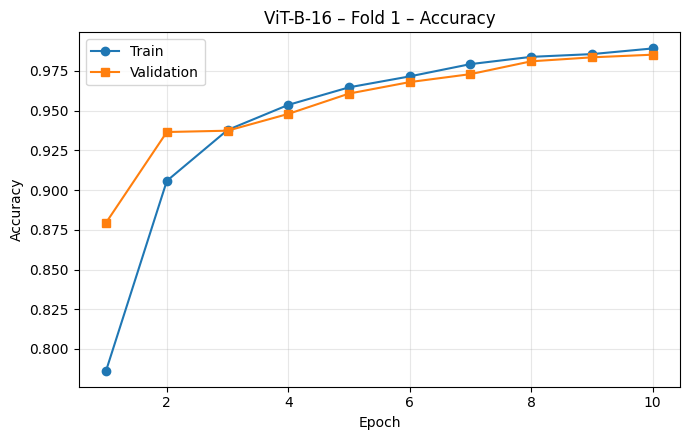

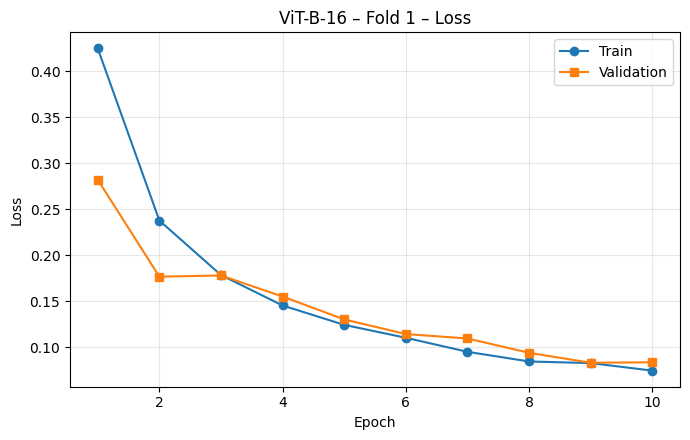

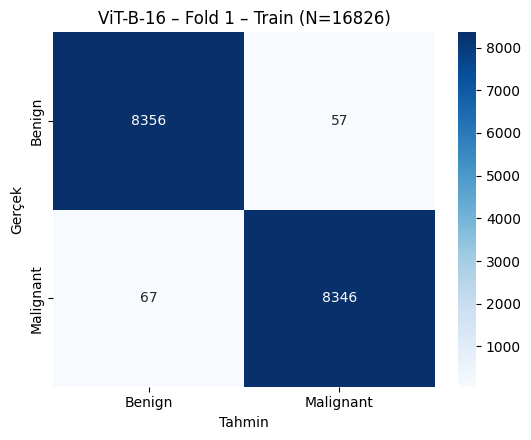

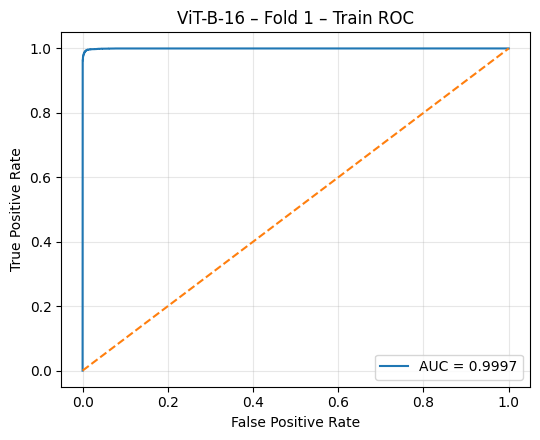

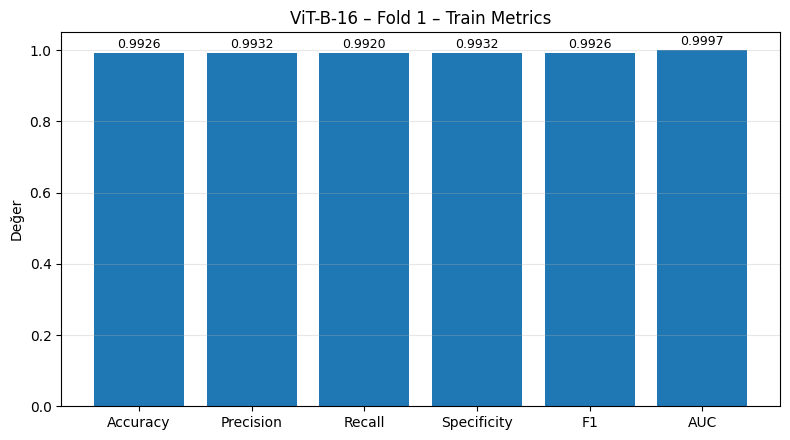

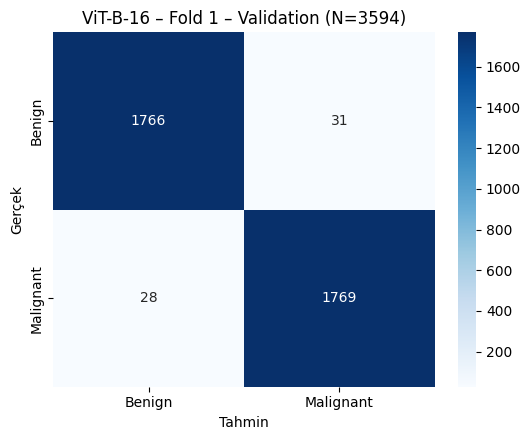

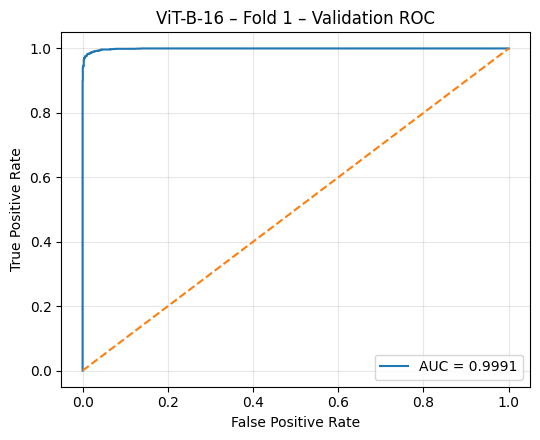

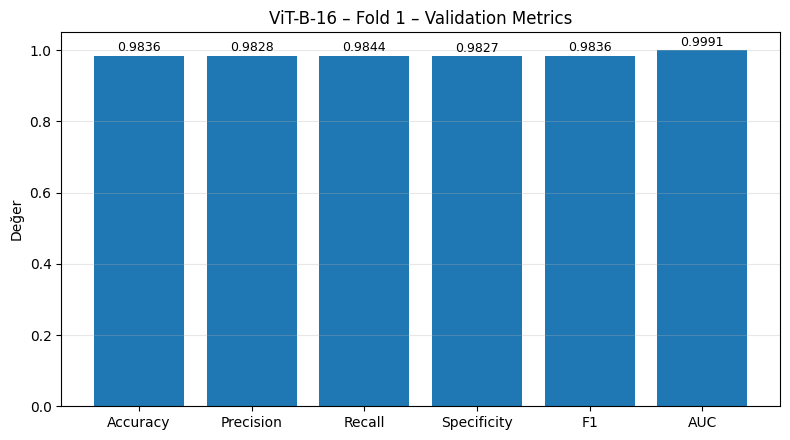

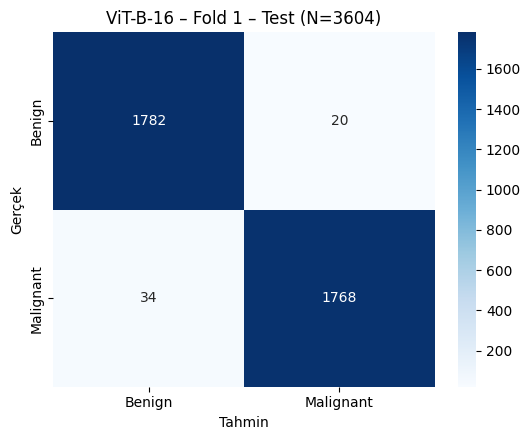

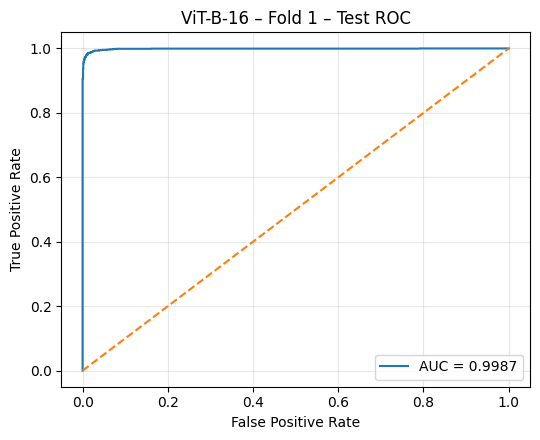

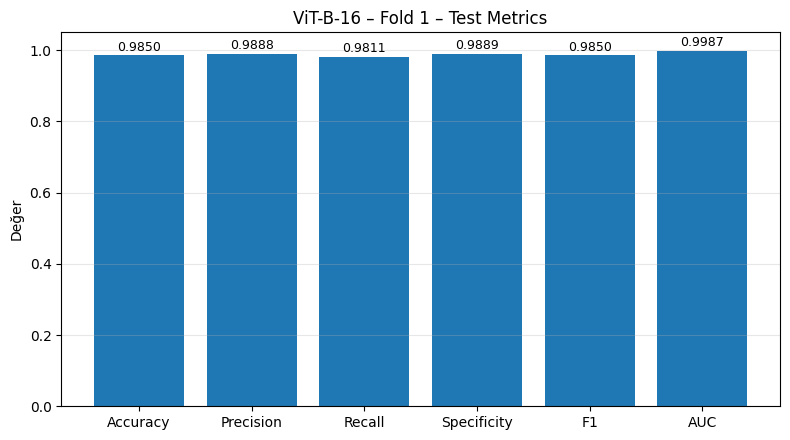

ViT-B-16 – Fold 1 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8356.0,57.0,67.0,8346.0,0.992630,0.993217,0.992036,0.993225,0.992626,0.999732,0.068694
Validation,3594.0,1766.0,31.0,28.0,1769.0,0.983584,0.982778,0.984418,0.982749,0.983597,0.999113,0.083045
Test,3604.0,1782.0,20.0,34.0,1768.0,0.985017,0.988814,0.981132,0.988901,0.984958,0.998726,0.082938


✓ ViT-B-16 Fold 1: best epoch 9 | Test acc 0.9850
ViT-B-16 | Fold 2 | Epoch 01/10 | Train loss 0.4301 acc 0.7822 | Val loss 0.2862 acc 0.8787
ViT-B-16 | Fold 2 | Epoch 02/10 | Train loss 0.2319 acc 0.9076 | Val loss 0.1913 acc 0.9277
ViT-B-16 | Fold 2 | Epoch 03/10 | Train loss 0.1765 acc 0.9379 | Val loss 0.1776 acc 0.9410
ViT-B-16 | Fold 2 | Epoch 04/10 | Train loss 0.1441 acc 0.9542 | Val loss 0.1225 acc 0.9608
ViT-B-16 | Fold 2 | Epoch 05/10 | Train loss 0.1223 acc 0.9667 | Val loss 0.1090 acc 0.9711
ViT-B-16 | Fold 2 | Epoch 06/10 | Train loss 0.1079 acc 0.9725 | Val loss 0.1153 acc 0.9699
ViT-B-16 | Fold 2 | Epoch 07/10 | Train loss 0.0934 acc 0.9801 | Val loss 0.0943 acc 0.9797
ViT-B-16 | Fold 2 | Epoch 08/10 | Train loss 0.0832 acc 0.9849 | Val loss 0.0926 acc 0.9805
ViT-B-16 | Fold 2 | Epoch 09/10 | Train loss 0.0758 acc 0.9884 | Val loss 0.0866 acc 0.9827
ViT-B-16 | Fold 2 | Epoch 10/10 | Train loss 0.0733 acc 0.9894 | Val loss 0.0854 acc 0.9833


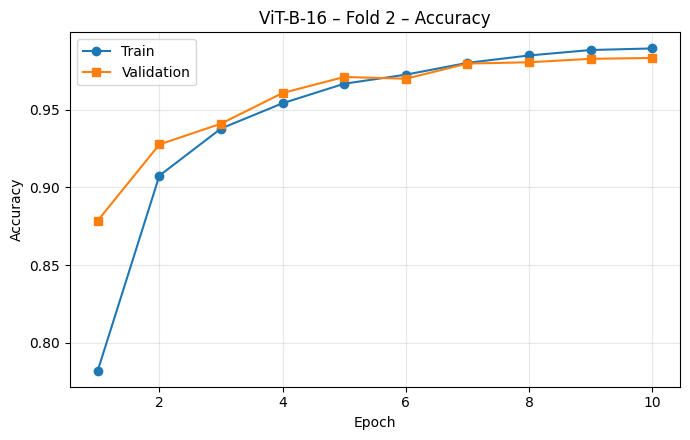

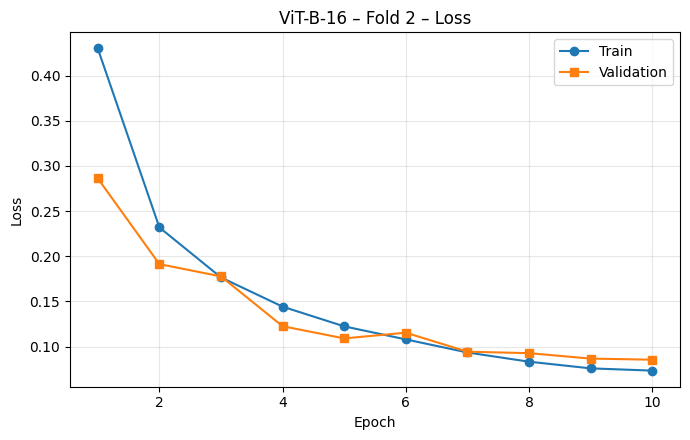

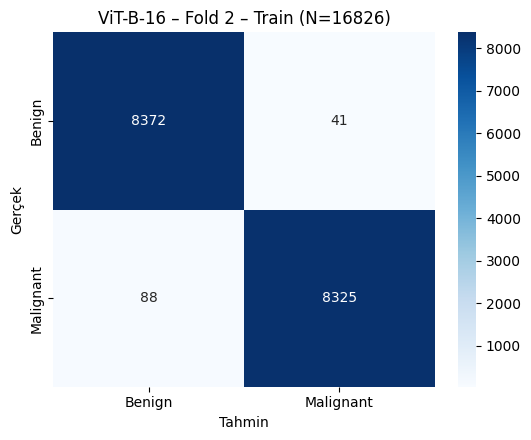

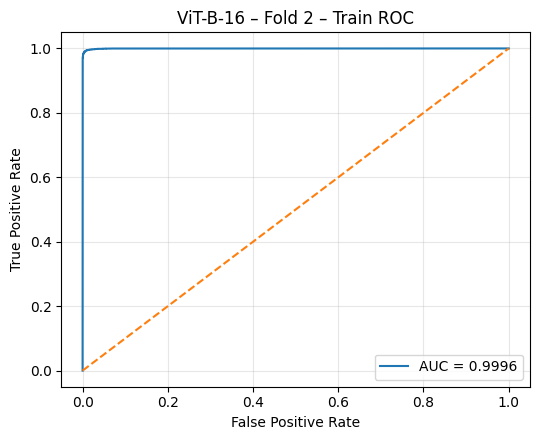

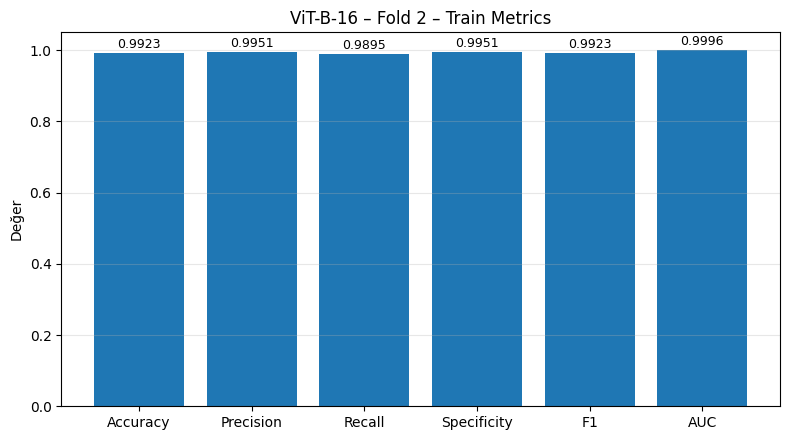

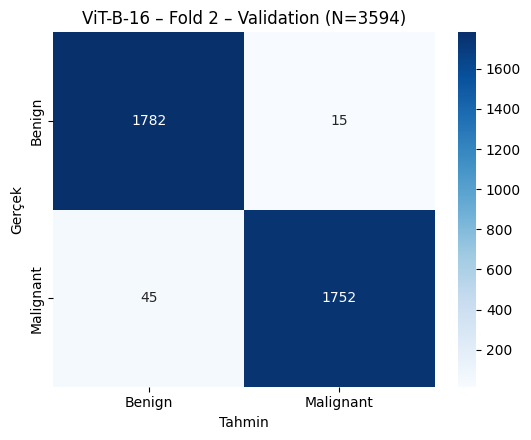

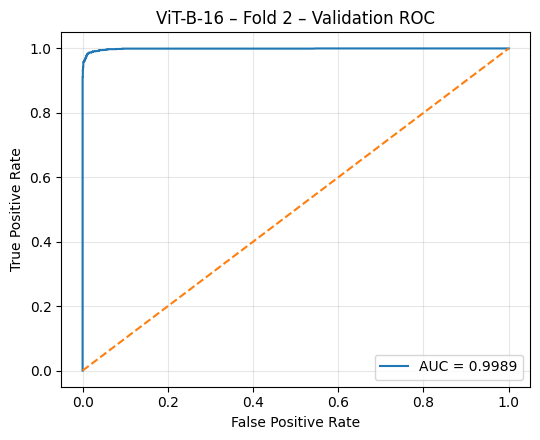

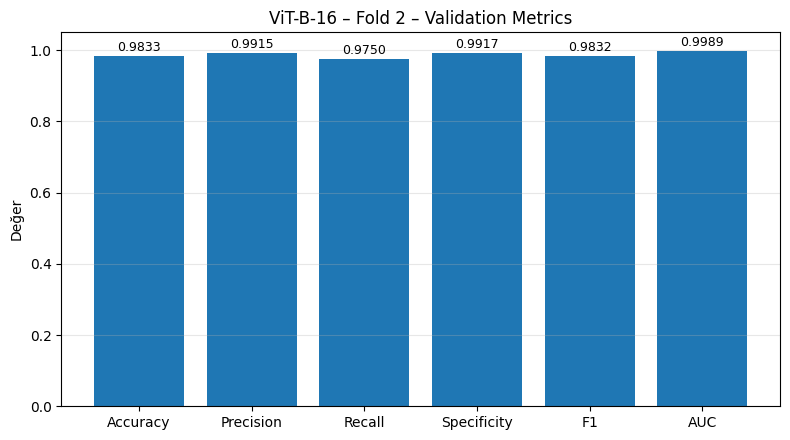

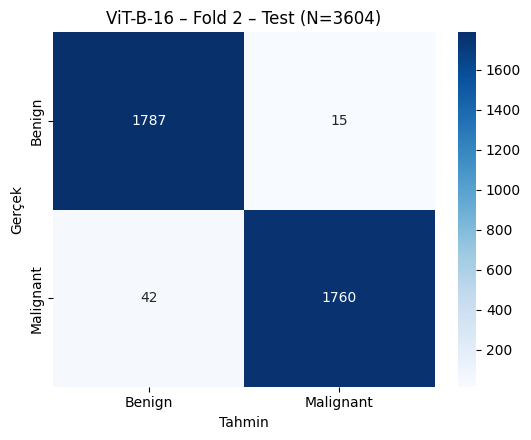

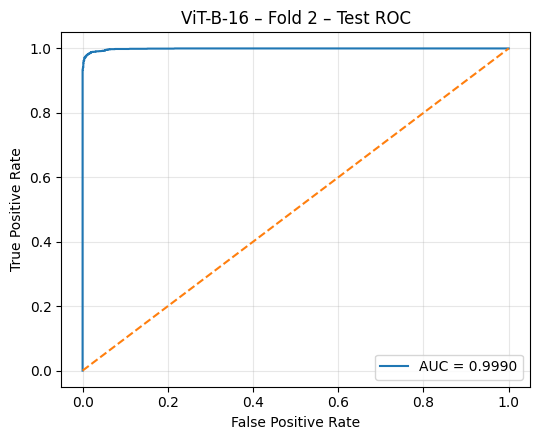

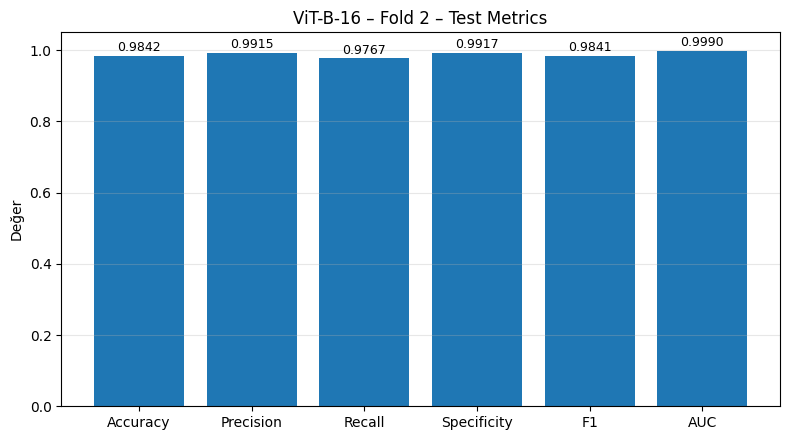

ViT-B-16 – Fold 2 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8372.0,41.0,88.0,8325.0,0.992333,0.995099,0.989540,0.995127,0.992312,0.999641,0.067196
Validation,3594.0,1782.0,15.0,45.0,1752.0,0.983306,0.991511,0.974958,0.991653,0.983165,0.998875,0.085392
Test,3604.0,1787.0,15.0,42.0,1760.0,0.984184,0.991549,0.976693,0.991676,0.984065,0.998987,0.084394


✓ ViT-B-16 Fold 2: best epoch 10 | Test acc 0.9842
ViT-B-16 | Fold 3 | Epoch 01/10 | Train loss 0.4326 acc 0.7836 | Val loss 0.2656 acc 0.8893
ViT-B-16 | Fold 3 | Epoch 02/10 | Train loss 0.2388 acc 0.9032 | Val loss 0.2102 acc 0.9143
ViT-B-16 | Fold 3 | Epoch 03/10 | Train loss 0.1750 acc 0.9378 | Val loss 0.1647 acc 0.9524
ViT-B-16 | Fold 3 | Epoch 04/10 | Train loss 0.1436 acc 0.9548 | Val loss 0.1220 acc 0.9672
ViT-B-16 | Fold 3 | Epoch 05/10 | Train loss 0.1234 acc 0.9646 | Val loss 0.1232 acc 0.9697
ViT-B-16 | Fold 3 | Epoch 06/10 | Train loss 0.1100 acc 0.9726 | Val loss 0.0962 acc 0.9819
ViT-B-16 | Fold 3 | Epoch 07/10 | Train loss 0.0935 acc 0.9803 | Val loss 0.0844 acc 0.9861
ViT-B-16 | Fold 3 | Epoch 08/10 | Train loss 0.0869 acc 0.9838 | Val loss 0.0813 acc 0.9869
ViT-B-16 | Fold 3 | Epoch 09/10 | Train loss 0.0772 acc 0.9879 | Val loss 0.0746 acc 0.9883
ViT-B-16 | Fold 3 | Epoch 10/10 | Train loss 0.0737 acc 0.9901 | Val loss 0.0752 acc 0.9875


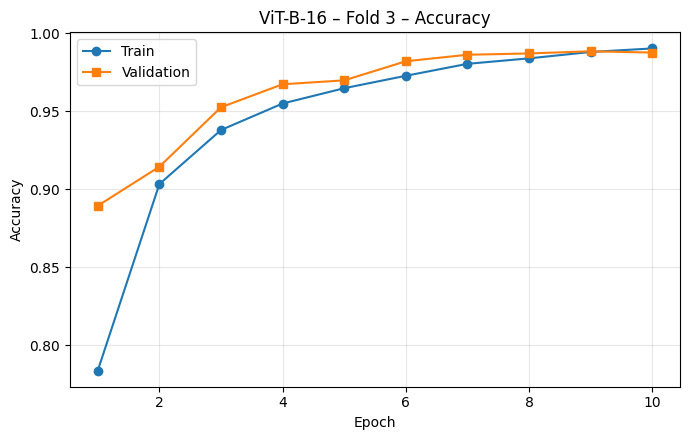

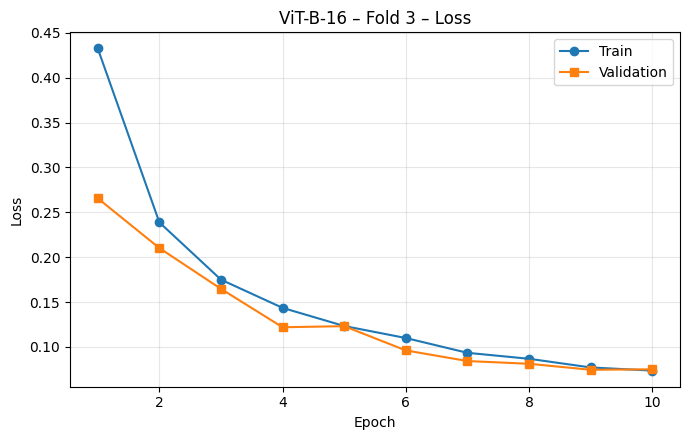

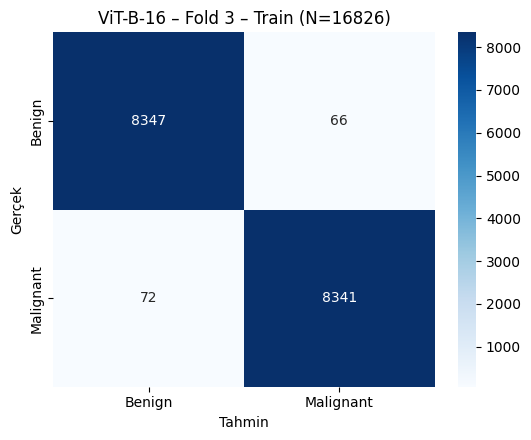

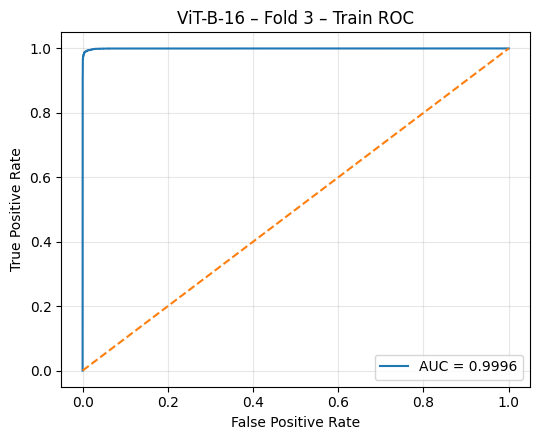

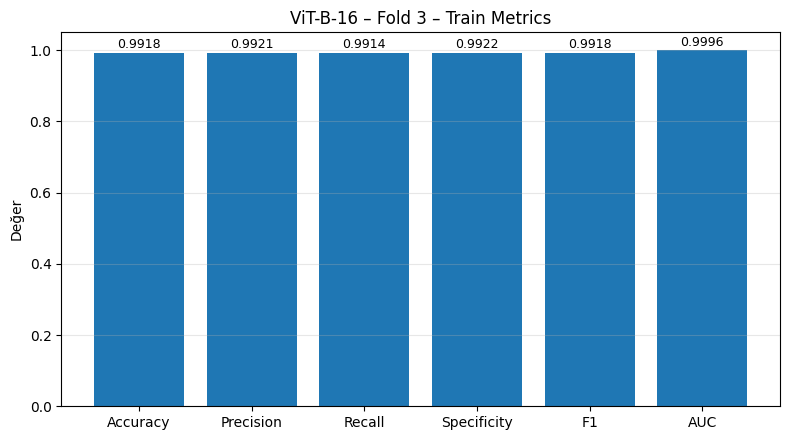

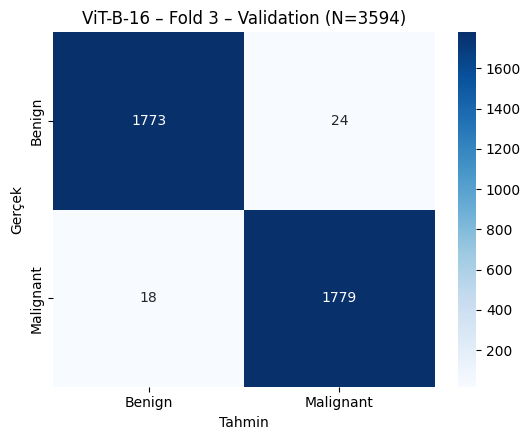

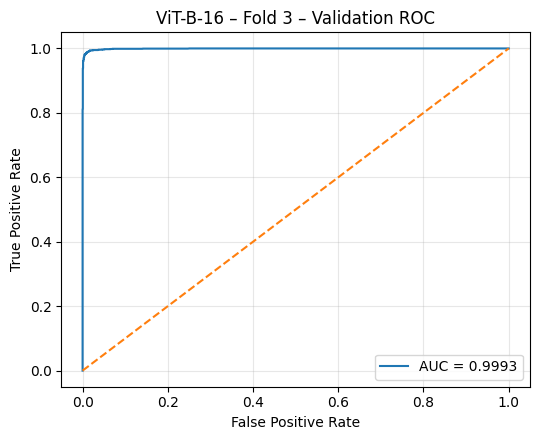

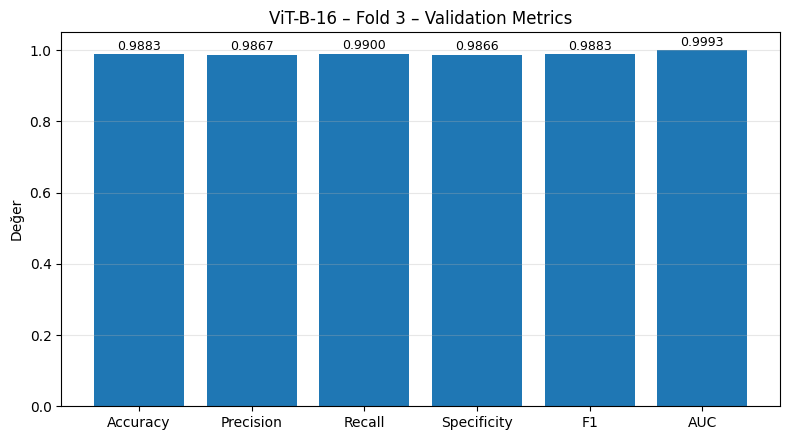

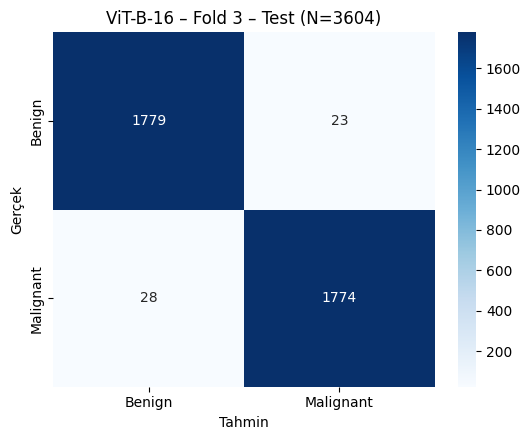

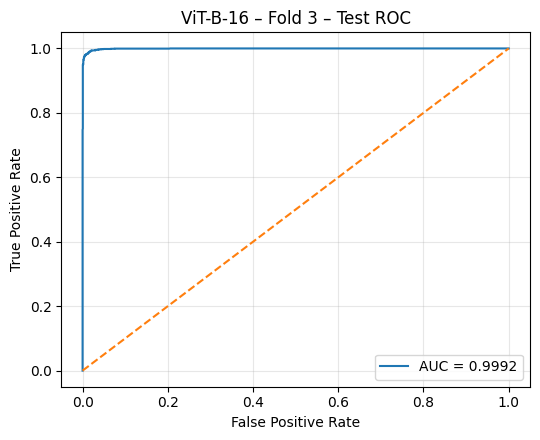

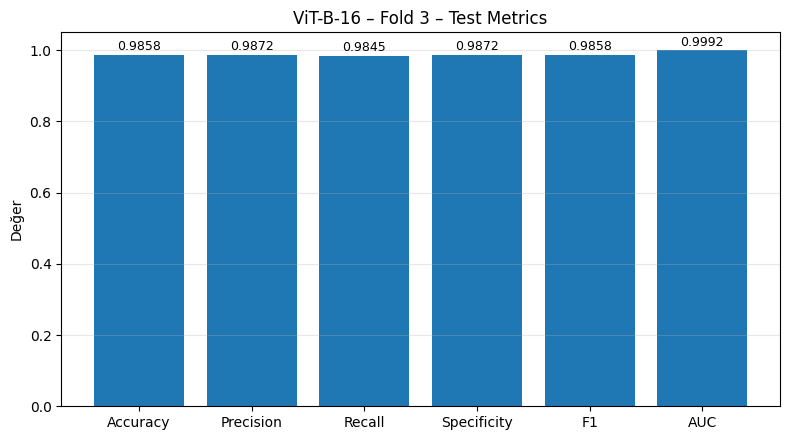

ViT-B-16 – Fold 3 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8347.0,66.0,72.0,8341.0,0.991798,0.992149,0.991442,0.992155,0.991795,0.999551,0.067191
Validation,3594.0,1773.0,24.0,18.0,1779.0,0.988314,0.986689,0.989983,0.986644,0.988333,0.999256,0.074605
Test,3604.0,1779.0,23.0,28.0,1774.0,0.985849,0.987201,0.984462,0.987236,0.985829,0.999249,0.076147


✓ ViT-B-16 Fold 3: best epoch 9 | Test acc 0.9858
ViT-B-16 | Fold 4 | Epoch 01/10 | Train loss 0.4218 acc 0.7901 | Val loss 0.2512 acc 0.8918
ViT-B-16 | Fold 4 | Epoch 02/10 | Train loss 0.2308 acc 0.9089 | Val loss 0.1785 acc 0.9393
ViT-B-16 | Fold 4 | Epoch 03/10 | Train loss 0.1716 acc 0.9414 | Val loss 0.1720 acc 0.9380
ViT-B-16 | Fold 4 | Epoch 04/10 | Train loss 0.1419 acc 0.9579 | Val loss 0.1357 acc 0.9610
ViT-B-16 | Fold 4 | Epoch 05/10 | Train loss 0.1186 acc 0.9672 | Val loss 0.1163 acc 0.9686
ViT-B-16 | Fold 4 | Epoch 06/10 | Train loss 0.1034 acc 0.9766 | Val loss 0.1068 acc 0.9719
ViT-B-16 | Fold 4 | Epoch 07/10 | Train loss 0.0911 acc 0.9809 | Val loss 0.0936 acc 0.9783
ViT-B-16 | Fold 4 | Epoch 08/10 | Train loss 0.0846 acc 0.9851 | Val loss 0.0944 acc 0.9797
ViT-B-16 | Fold 4 | Epoch 09/10 | Train loss 0.0789 acc 0.9871 | Val loss 0.0855 acc 0.9847
ViT-B-16 | Fold 4 | Epoch 10/10 | Train loss 0.0749 acc 0.9892 | Val loss 0.0855 acc 0.9841


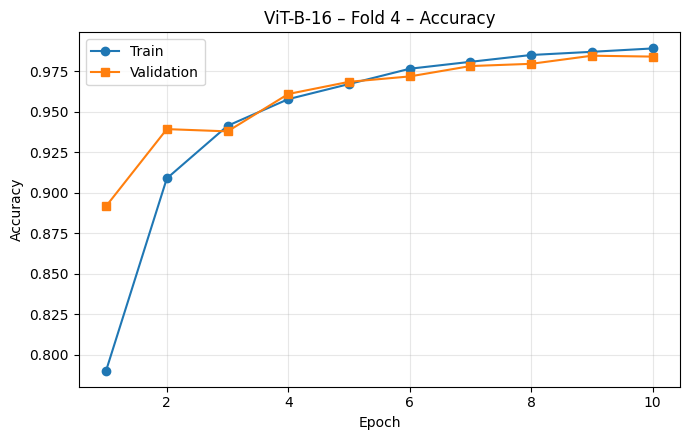

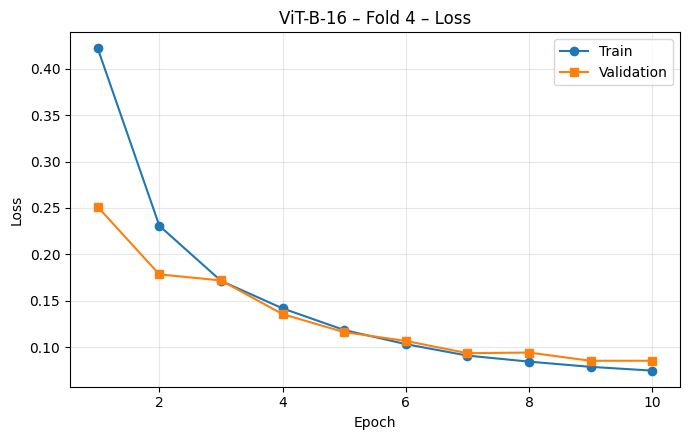

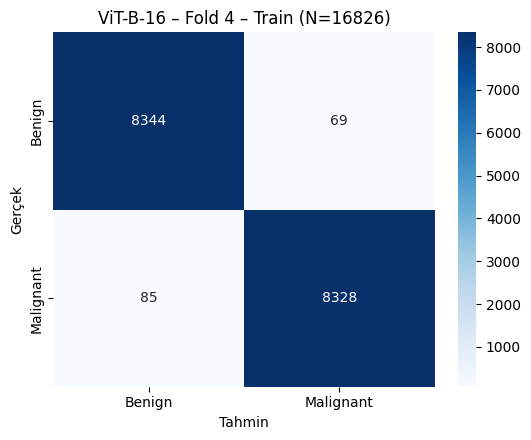

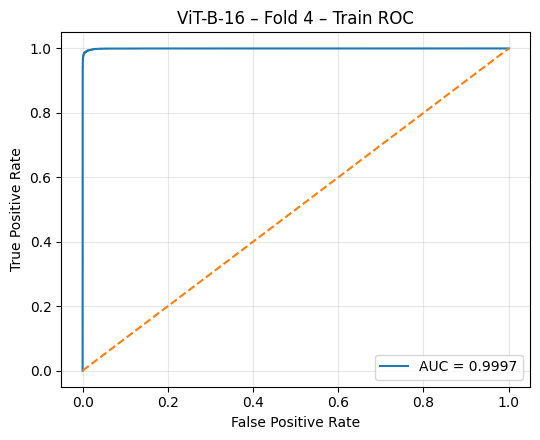

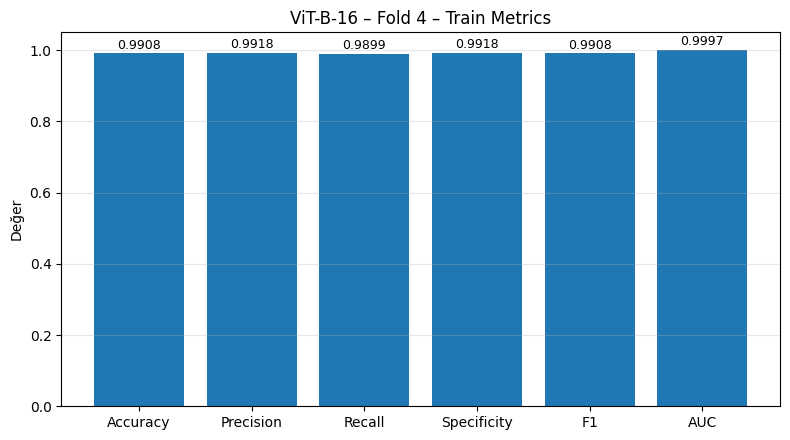

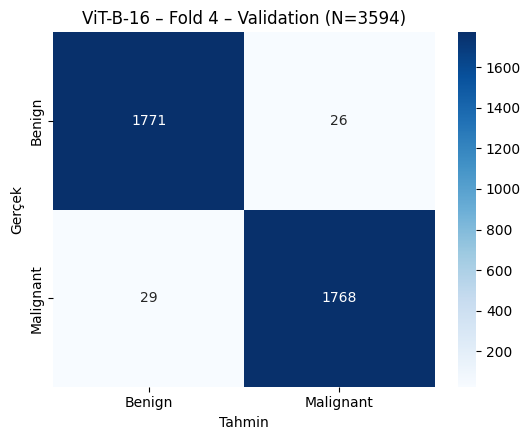

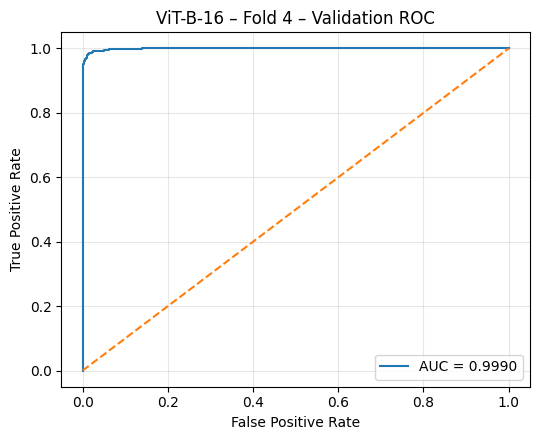

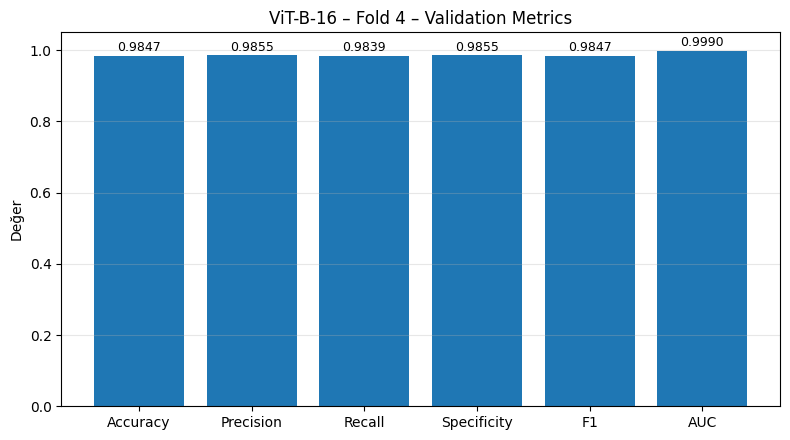

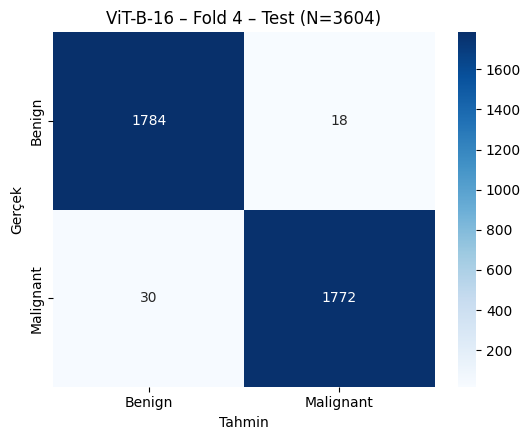

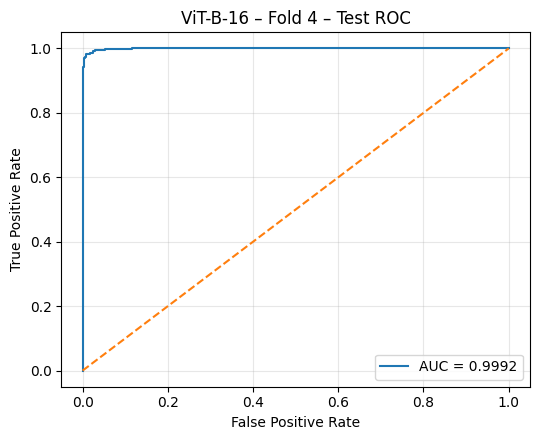

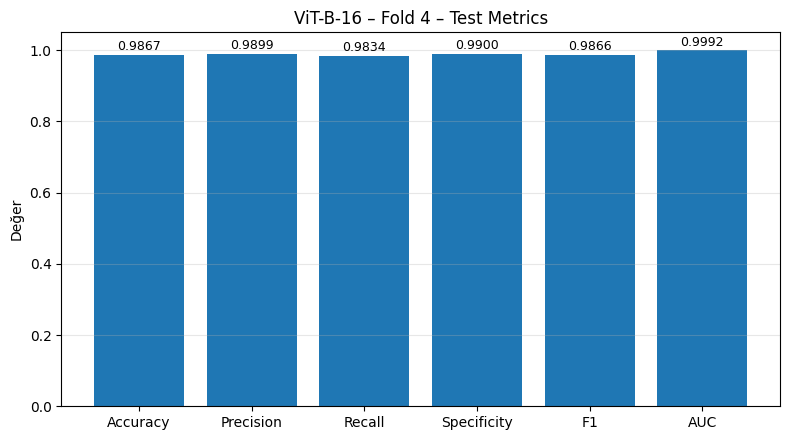

ViT-B-16 – Fold 4 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8344.0,69.0,85.0,8328.0,0.990847,0.991783,0.989897,0.991798,0.990839,0.999681,0.069392
Validation,3594.0,1771.0,26.0,29.0,1768.0,0.984697,0.985507,0.983862,0.985531,0.984684,0.998982,0.085467
Test,3604.0,1784.0,18.0,30.0,1772.0,0.986681,0.989944,0.983352,0.990011,0.986637,0.999161,0.081406


✓ ViT-B-16 Fold 4: best epoch 9 | Test acc 0.9867
ViT-B-16 | Fold 5 | Epoch 01/10 | Train loss 0.4238 acc 0.7877 | Val loss 0.2579 acc 0.8859
ViT-B-16 | Fold 5 | Epoch 02/10 | Train loss 0.2298 acc 0.9111 | Val loss 0.1911 acc 0.9290
ViT-B-16 | Fold 5 | Epoch 03/10 | Train loss 0.1703 acc 0.9415 | Val loss 0.1353 acc 0.9541
ViT-B-16 | Fold 5 | Epoch 04/10 | Train loss 0.1439 acc 0.9552 | Val loss 0.1260 acc 0.9622
ViT-B-16 | Fold 5 | Epoch 05/10 | Train loss 0.1214 acc 0.9663 | Val loss 0.1106 acc 0.9716
ViT-B-16 | Fold 5 | Epoch 06/10 | Train loss 0.1056 acc 0.9744 | Val loss 0.0975 acc 0.9780
ViT-B-16 | Fold 5 | Epoch 07/10 | Train loss 0.0934 acc 0.9795 | Val loss 0.0913 acc 0.9808
ViT-B-16 | Fold 5 | Epoch 08/10 | Train loss 0.0842 acc 0.9848 | Val loss 0.0867 acc 0.9833
ViT-B-16 | Fold 5 | Epoch 09/10 | Train loss 0.0777 acc 0.9885 | Val loss 0.0816 acc 0.9880
ViT-B-16 | Fold 5 | Epoch 10/10 | Train loss 0.0739 acc 0.9903 | Val loss 0.0781 acc 0.9869


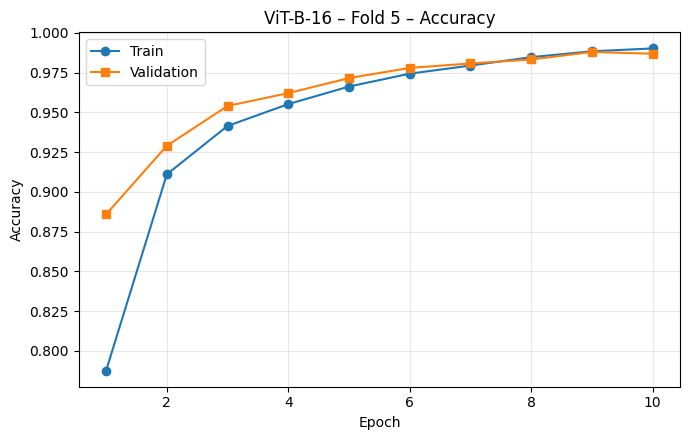

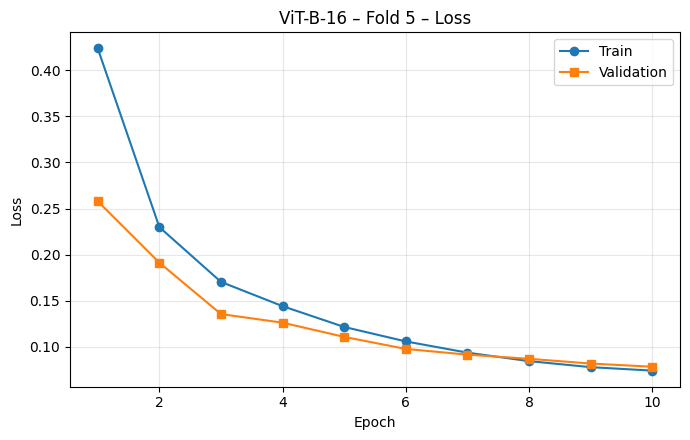

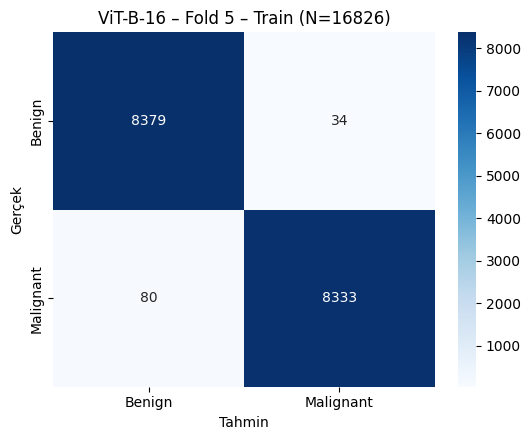

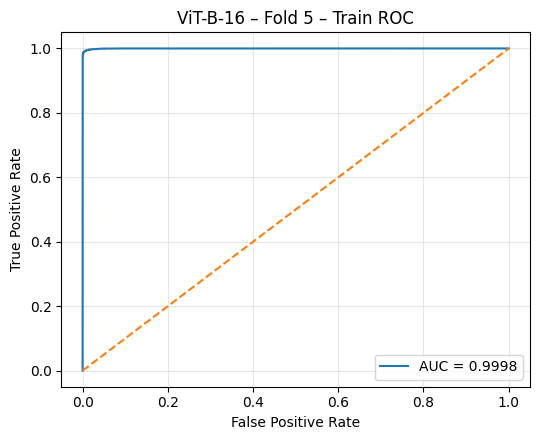

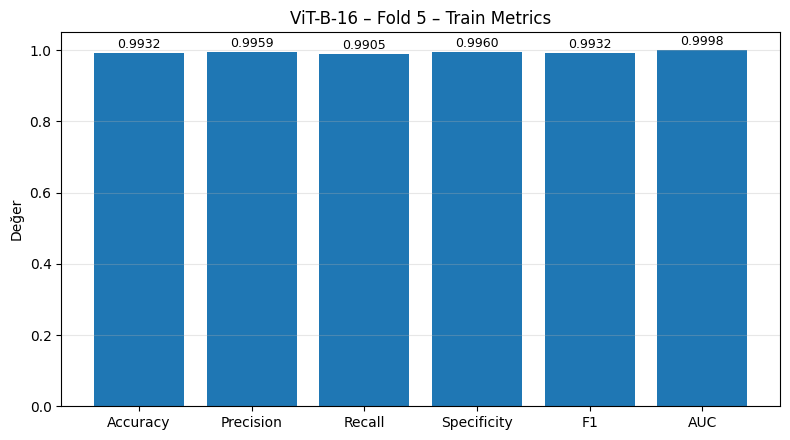

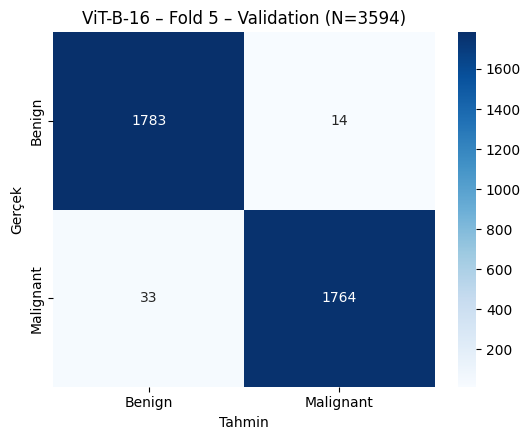

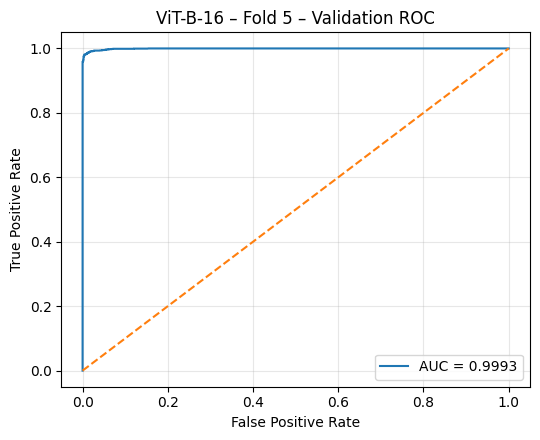

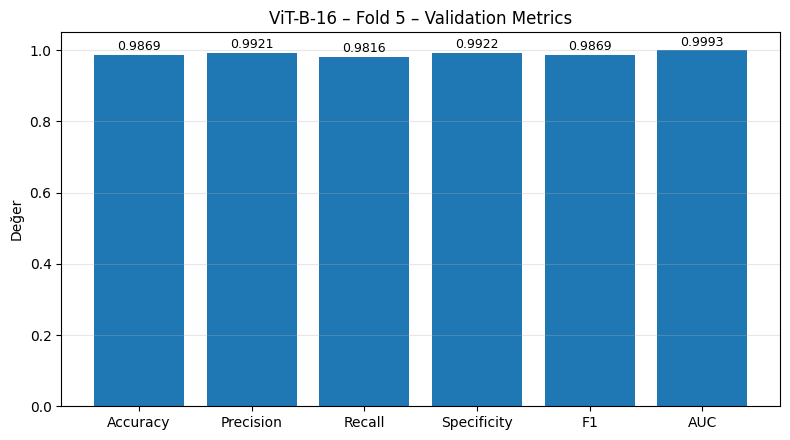

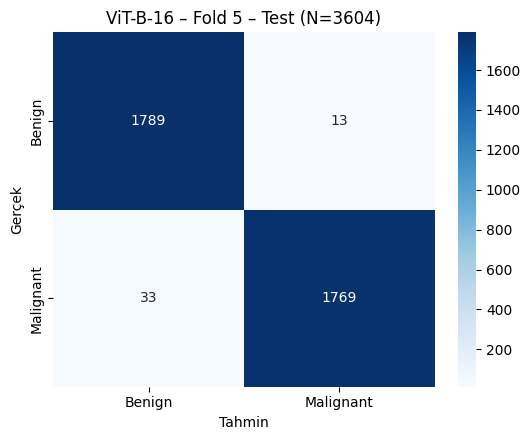

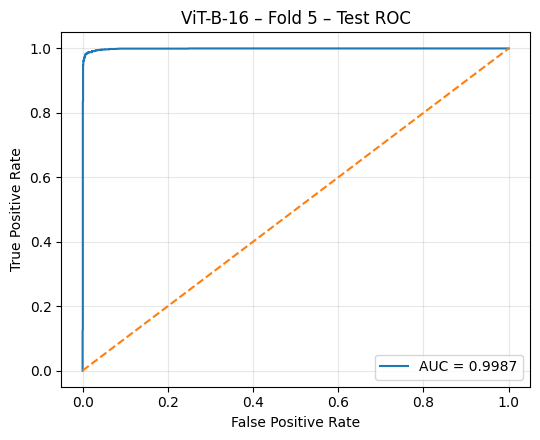

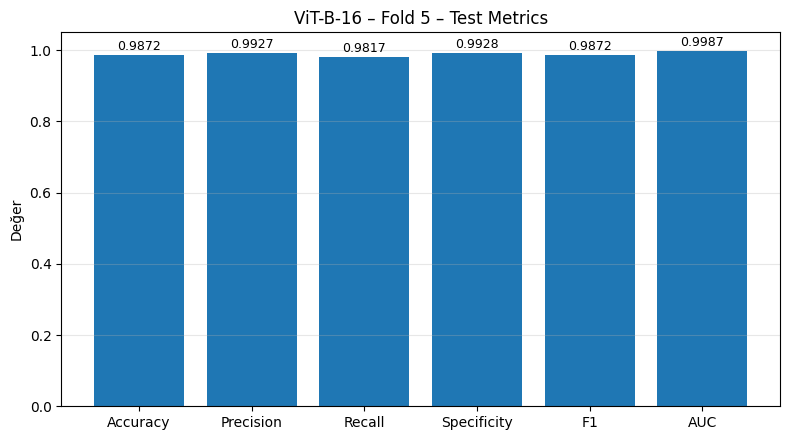

ViT-B-16 – Fold 5 sonuçları (best epoch = 10):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8379.0,34.0,80.0,8333.0,0.993225,0.995936,0.990491,0.995959,0.993206,0.999797,0.066568
Validation,3594.0,1783.0,14.0,33.0,1764.0,0.986923,0.992126,0.981636,0.992209,0.986853,0.999303,0.078141
Test,3604.0,1789.0,13.0,33.0,1769.0,0.987236,0.992705,0.981687,0.992786,0.987165,0.998719,0.080220


✓ ViT-B-16 Fold 5: best epoch 10 | Test acc 0.9872
Downloading: "https://download.pytorch.org/models/vit_b_32-d86f8d99.pth" to /root/.cache/torch/hub/checkpoints/vit_b_32-d86f8d99.pth


100%|██████████| 337M/337M [00:02<00:00, 148MB/s]


ViT-B-32 | Fold 1 | Epoch 01/10 | Train loss 0.4253 acc 0.7855 | Val loss 0.2959 acc 0.8676
ViT-B-32 | Fold 1 | Epoch 02/10 | Train loss 0.2389 acc 0.9055 | Val loss 0.1975 acc 0.9285
ViT-B-32 | Fold 1 | Epoch 03/10 | Train loss 0.1811 acc 0.9356 | Val loss 0.2079 acc 0.9179
ViT-B-32 | Fold 1 | Epoch 04/10 | Train loss 0.1516 acc 0.9522 | Val loss 0.1380 acc 0.9619
ViT-B-32 | Fold 1 | Epoch 05/10 | Train loss 0.1304 acc 0.9624 | Val loss 0.1323 acc 0.9605
ViT-B-32 | Fold 1 | Epoch 06/10 | Train loss 0.1128 acc 0.9710 | Val loss 0.0891 acc 0.9819
ViT-B-32 | Fold 1 | Epoch 07/10 | Train loss 0.0968 acc 0.9778 | Val loss 0.0864 acc 0.9847
ViT-B-32 | Fold 1 | Epoch 08/10 | Train loss 0.0862 acc 0.9844 | Val loss 0.0792 acc 0.9864
ViT-B-32 | Fold 1 | Epoch 09/10 | Train loss 0.0808 acc 0.9869 | Val loss 0.0735 acc 0.9908
ViT-B-32 | Fold 1 | Epoch 10/10 | Train loss 0.0777 acc 0.9881 | Val loss 0.0737 acc 0.9889


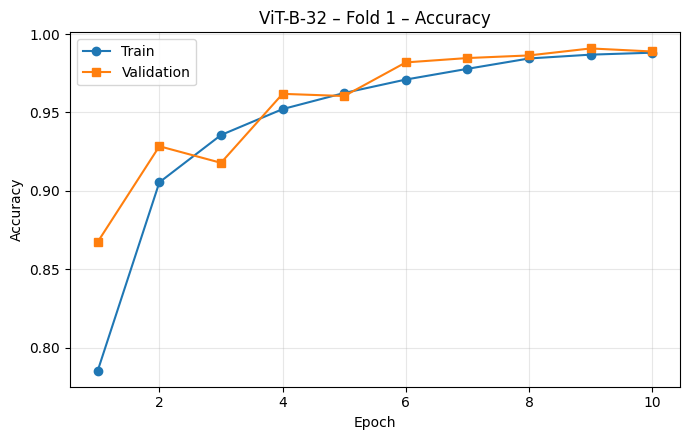

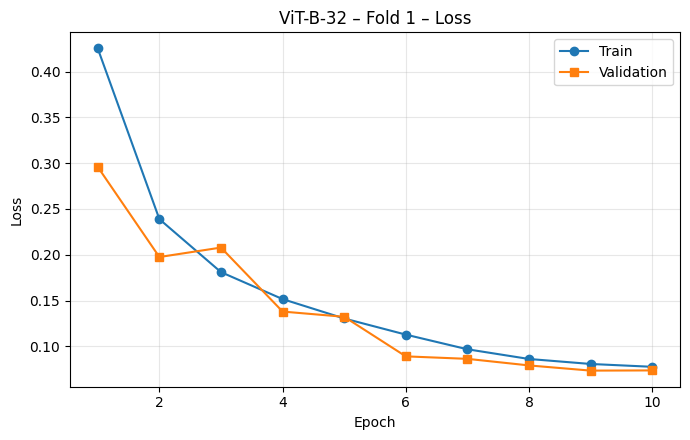

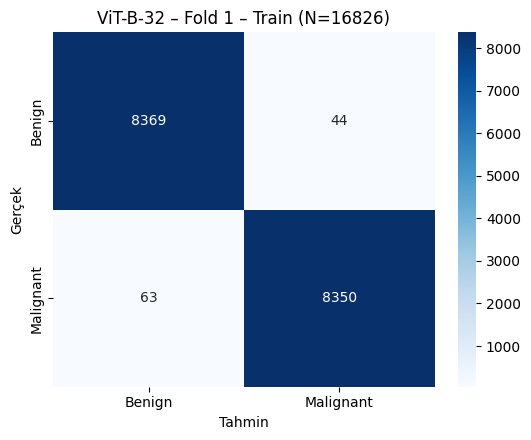

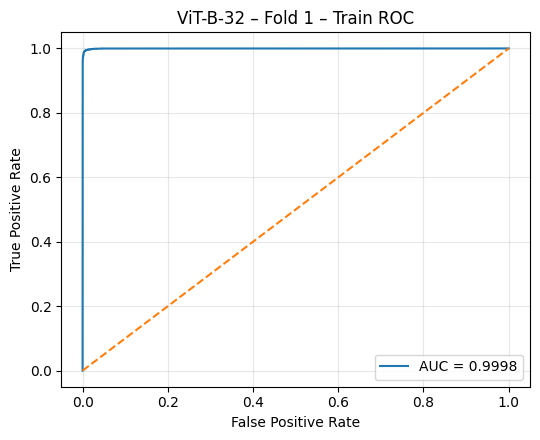

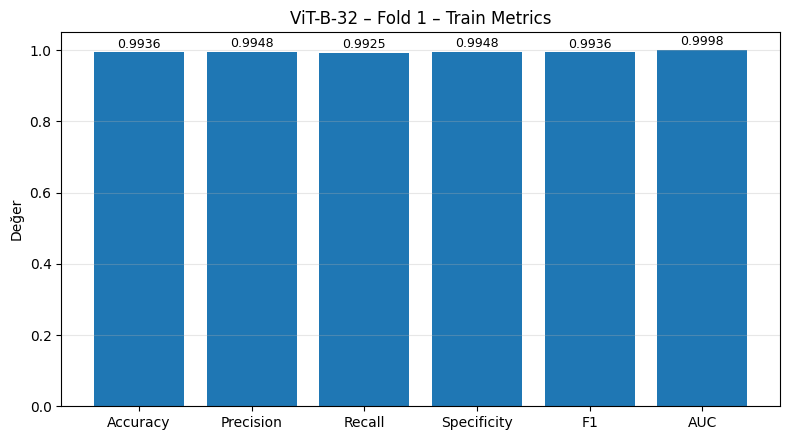

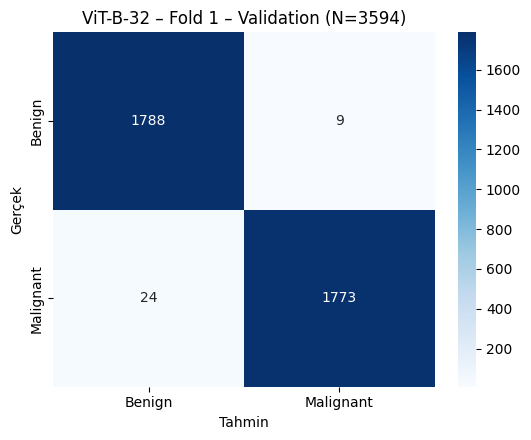

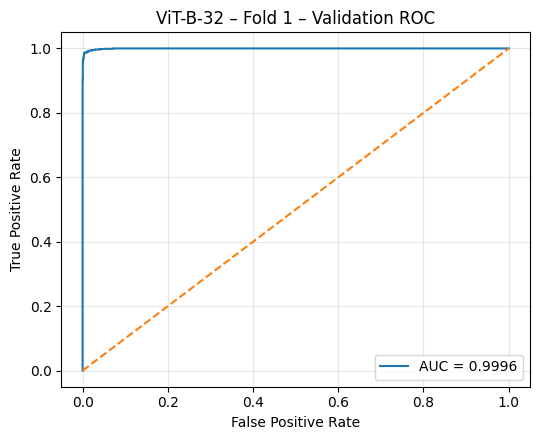

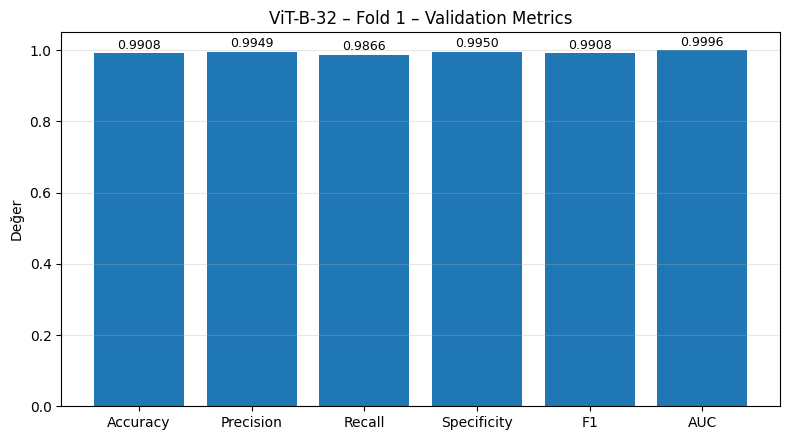

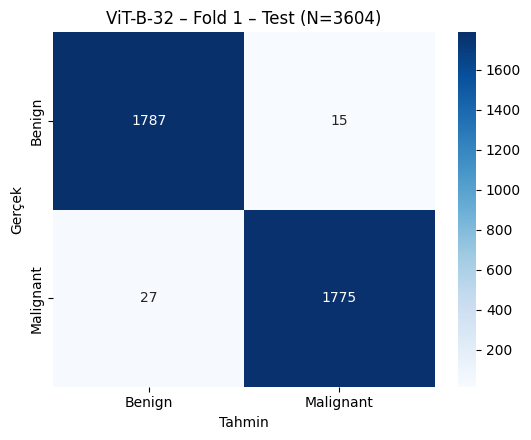

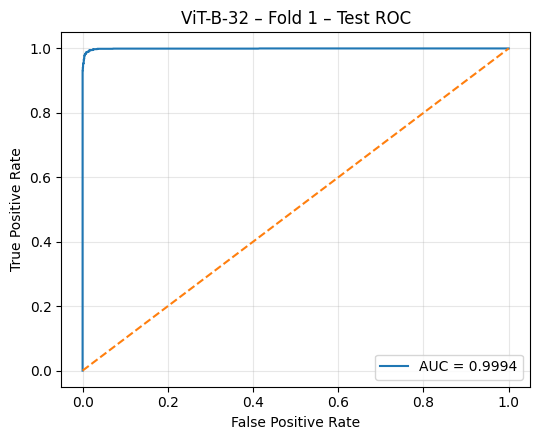

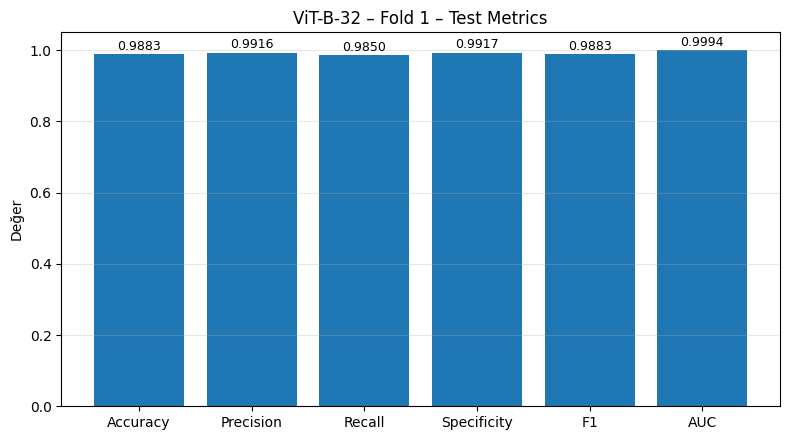

ViT-B-32 – Fold 1 sonuçları (best epoch = 9):


,N,TN,FP,FN,TP,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score,ROC-AUC,Loss
Train,16826.0,8369.0,44.0,63.0,8350.0,0.993641,0.994758,0.992512,0.994770,0.993634,0.999795,0.065908
Validation,3594.0,1788.0,9.0,24.0,1773.0,0.990818,0.994949,0.986644,0.994992,0.990780,0.999560,0.073525
Test,3604.0,1787.0,15.0,27.0,1775.0,0.988346,0.991620,0.985017,0.991676,0.988307,0.999356,0.075056


✓ ViT-B-32 Fold 1: best epoch 9 | Test acc 0.9883
ViT-B-32 | Fold 2 | Epoch 01/10 | Train loss 0.4183 acc 0.7953 | Val loss 0.2643 acc 0.8862
ViT-B-32 | Fold 2 | Epoch 02/10 | Train loss 0.2324 acc 0.9087 | Val loss 0.1713 acc 0.9416


In [ ]:
# ======================= 4. ÇALIŞTIR =======================
KIND, FAM = GROUP.split("_")
models_to_run = MODELS or (CNN_MODELS if FAM == "cnn" else VIT_MODELS)
assert all(FAMILY[m] == FAM for m in models_to_run), "Seçilen modeller gruba uymuyor"
if RERUN:   # etiket başına bir kez: MODELS=None ise gruptaki TÜM modeller, değilse sadece MODELS'tekiler
    marker = OUTPUT_ROOT / CV_MODE / GROUP / f"rerun_{RERUN}.done"
    if marker.exists():
        print(f"RERUN '{RERUN}' daha önce uygulanmış → silme YAPILMADI, kaldığı fold'dan devam ediliyor.")
    else:
        for m in models_to_run:
            d = OUTPUT_ROOT / CV_MODE / GROUP / m
            if d.exists():
                shutil.rmtree(d); print(f"Eski sonuçlar silindi, yeniden eğitilecek: {d}")
        marker.parent.mkdir(parents=True, exist_ok=True)
        marker.write_text(f"{time.strftime('%Y-%m-%d %H:%M')} | silinen modeller: {', '.join(models_to_run)}\n")

(OUTPUT_ROOT / CV_MODE / GROUP).mkdir(parents=True, exist_ok=True)
(OUTPUT_ROOT / CV_MODE / GROUP / "config.json").write_text(json.dumps({
    "GROUP": GROUP, "COMMON": COMMON, "RECIPE": RECIPES[KIND], "FT_SCOPE": FT_SCOPE[(KIND, FAM)],
    "AUGMENT": AUGMENT if RECIPES[KIND]["augment"] else None, "CV_MODE": CV_MODE, "N_FOLDS": N_FOLDS, "FOLD_SEED": FOLD_SEED, "TRAIN_SEED": TRAIN_SEED,
    "fold_counts": fold_table.to_dict("records"), "VIT_LAST_BLOCKS": VIT_LAST_BLOCKS,
    "torch": torch.__version__, "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu",
    "kaggle_split_counts": {s: len(d) for s, d in DS.items()}}, indent=2, default=str))

results = []
for name in models_to_run:
    for fold in range(1, N_FOLDS + 1):
        results.append(run_one(name, fold, KIND))

per_run, summary, article = results_to_frames(results)
with pd.ExcelWriter(OUTPUT_ROOT / CV_MODE / GROUP / f"{GROUP}_results.xlsx") as xw:
    per_run.to_excel(xw, sheet_name="Fold bazlı", index=False)
    summary.to_excel(xw, sheet_name="Ortalama-Std", index=False)
    article.to_excel(xw, sheet_name="Makale tablosu", index=False)
display(article[article.Split == "Test"])
